# 04 — Fare-by-Hour Modeling

## Research Question

**How do trip characteristics, time, location, and local ride demand affect ride-hailing fares in Chicago?**

I build the model step by step instead of starting with the most complicated model.

The modeling process follows what I learn from each previous step:

1. Start with a simple **Baseline Linear Regression** using distance and duration.
2. If linear regression already explains a large amount of fare variation, expand it into a **Full Multiple Linear Regression** using time, location, and demand.
3. Examine the hourly fare pattern. If the relationship looks nonlinear, try **Polynomial Ridge Regression** and use GridSearchCV to choose the polynomial degree and Ridge regularization strength.
4. Because the richer models contain many categorical variables and possible interactions, compare them with **Gradient Boosting**, which can learn nonlinear relationships and interactions automatically.
5. Compare all models and decide whether the extra complexity produces a meaningful improvement.
6. Use the Polynomial Ridge model to study the two variables most relevant to the project: **hour of day** and **relative demand**.

All four models use the **same 80/20 train-test split**, so the performance comparison is fair.


## Import Libraries

DuckDB is used to query the large Parquet dataset without loading all 55 million rows into memory. Pandas and NumPy are used for analysis, Plotly for visualization, and scikit-learn for modeling.


In [2]:
import duckdb
import pandas as pd
import numpy as np
import plotly.express as px

from pathlib import Path

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error


## Settings

The cleaned dataset contains more than 55 million trips. Training every exploratory model on all 55 million rows would be unnecessarily expensive, so I use a reproducible sample of approximately 500,000 trips for model fitting.

The **full dataset is still used to calculate local demand**, so the demand variable is not based only on the modeling sample.


In [3]:
PROCESSED_DIR = Path('../data/processed')
REPORTS_DIR = Path('../reports')
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

CLEAN_FILE = PROCESSED_DIR / 'rideshare_2025_clean.parquet'

SAMPLE_SIZE = 500_000
TUNE_SIZE = 100_000
RANDOM_STATE = 42

if not CLEAN_FILE.exists():
    raise FileNotFoundError('Cleaned dataset not found. Run code/02_data_cleaning.ipynb first.')

CLEAN_FILE


PosixPath('../data/processed/rideshare_2025_clean.parquet')

## Load the Cleaned Dataset

Verify the size and date range of the cleaned data.


In [5]:
con = duckdb.connect()

con.execute(f'''
    CREATE OR REPLACE VIEW rideshare AS
    SELECT *
    FROM read_parquet('{CLEAN_FILE.as_posix()}')
''')

con.sql('''
    SELECT
        COUNT(*) AS total_rows,
        MIN(trip_start_timestamp) AS first_trip,
        MAX(trip_start_timestamp) AS last_trip
    FROM rideshare
''').show()


┌────────────┬─────────────────────┬─────────────────────┐
│ total_rows │     first_trip      │      last_trip      │
│   int64    │      timestamp      │      timestamp      │
├────────────┼─────────────────────┼─────────────────────┤
│   55075632 │ 2025-01-01 00:00:00 │ 2025-12-31 23:45:00 │
└────────────┴─────────────────────┴─────────────────────┘



# Feature Engineering

Variables representing the main parts of a rideshare trip:

- trip distance and duration
- time of day
- day and month
- pickup and drop-off location
- local ride demand
- holiday status

I also keep coordinates because they may be useful later for the nonlinear model.


## Create Basic Trip and Time Features

`trip_seconds` is converted to minutes because minutes are easier to interpret. I also extract the hour, day of week, month, trip date, and pickup/drop-off coordinates.


In [6]:
con.execute('''
    CREATE OR REPLACE VIEW rideshare_features AS

    SELECT
        CAST(fare AS DOUBLE) AS fare,
        trip_miles,
        trip_seconds / 60.0 AS trip_minutes,

        pickup_community_area,
        dropoff_community_area,

        CAST(trip_start_timestamp AS DATE) AS trip_date,
        CAST(EXTRACT(HOUR FROM trip_start_timestamp) AS INTEGER) AS hour,
        CAST(EXTRACT(DOW FROM trip_start_timestamp) AS INTEGER) AS day_of_week,
        CAST(EXTRACT(MONTH FROM trip_start_timestamp) AS INTEGER) AS month,

        TRY_CAST(NULLIF(regexp_extract(
            pickup_centroid_location,
            'POINT \\((-?[0-9.]+) (-?[0-9.]+)\\)', 1
        ), '') AS DOUBLE) AS pickup_lon,

        TRY_CAST(NULLIF(regexp_extract(
            pickup_centroid_location,
            'POINT \\((-?[0-9.]+) (-?[0-9.]+)\\)', 2
        ), '') AS DOUBLE) AS pickup_lat,

        TRY_CAST(NULLIF(regexp_extract(
            dropoff_centroid_location,
            'POINT \\((-?[0-9.]+) (-?[0-9.]+)\\)', 1
        ), '') AS DOUBLE) AS dropoff_lon,

        TRY_CAST(NULLIF(regexp_extract(
            dropoff_centroid_location,
            'POINT \\((-?[0-9.]+) (-?[0-9.]+)\\)', 2
        ), '') AS DOUBLE) AS dropoff_lat

    FROM rideshare
''')


## Create a Local Demand Feature

The project is interested in dynamic pricing, so I need a variable that represents ride activity.

I define **local demand** as the number of trips beginning in the same pickup community area, on the same date, during the same hour.

This calculation uses the entire cleaned dataset.


In [7]:
con.execute('''
    CREATE OR REPLACE TEMP TABLE hourly_demand AS

    SELECT
        trip_date,
        day_of_week,
        hour,
        pickup_community_area,
        COUNT(*) AS local_demand

    FROM rideshare_features

    GROUP BY
        trip_date,
        day_of_week,
        hour,
        pickup_community_area
''')

con.sql('''
    SELECT *
    FROM hourly_demand
    ORDER BY local_demand DESC
    LIMIT 10
''').show()


┌────────────┬─────────────┬───────┬───────────────────────┬──────────────┐
│ trip_date  │ day_of_week │ hour  │ pickup_community_area │ local_demand │
│    date    │    int32    │ int32 │         int32         │    int64     │
├────────────┼─────────────┼───────┼───────────────────────┼──────────────┤
│ 2025-11-08 │           6 │    19 │                     8 │         4766 │
│ 2025-12-13 │           6 │    19 │                     8 │         4554 │
│ 2025-12-31 │           3 │    21 │                     8 │         4461 │
│ 2025-11-02 │           0 │     1 │                     8 │         4379 │
│ 2025-12-31 │           3 │    20 │                     8 │         4311 │
│ 2025-12-13 │           6 │    20 │                     8 │         4304 │
│ 2025-12-06 │           6 │    19 │                     8 │         4287 │
│ 2025-03-15 │           6 │    20 │                     8 │         4270 │
│ 2025-11-08 │           6 │    20 │                     8 │         4255 │
│ 2025-10-18

## Convert Raw Demand into Relative Demand

Raw trip count is not directly comparable across hours. For example, 300 trips may be unusually high at 4 AM but normal at 6 PM.

I therefore calculate **typical demand** for the same pickup area, weekday, and hour, then define:

**Demand Ratio = Local Demand / Typical Demand**

Interpretation:

- `1.0` = normal demand
- `1.5` = 50% higher than normal
- `2.0` = twice normal demand
- `0.5` = half normal demand


In [8]:
con.execute('''
    CREATE OR REPLACE TEMP TABLE typical_demand AS

    SELECT
        pickup_community_area,
        day_of_week,
        hour,
        AVG(local_demand) AS typical_demand

    FROM hourly_demand

    GROUP BY
        pickup_community_area,
        day_of_week,
        hour
''')


## Create a Holiday Indicator

Holiday travel may differ from a normal weekday or weekend, so I add an `is_holiday` indicator for major U.S. holidays in 2025.


In [9]:
holidays_2025 = [
    '2025-01-01', '2025-01-20', '2025-02-17', '2025-05-26',
    '2025-06-19', '2025-07-04', '2025-09-01', '2025-10-13',
    '2025-11-11', '2025-11-27', '2025-12-25'
]

holiday_sql = ', '.join(f"DATE '{date}'" for date in holidays_2025)


## Combine the Modeling Features

I now combine the trip, time, location, and demand variables.

I also create variables that may become useful as the models become more complex:

- `route`: pickup area → drop-off area
- `hour_day`: hour × weekday
- `pickup_hour`: pickup area × hour
- `dropoff_hour`: drop-off area × hour
- `avg_speed_mph`
- `crow_fly_miles`: straight-line distance between pickup and drop-off


In [10]:
con.execute(f'''
    CREATE OR REPLACE VIEW modeling_data AS

    SELECT
        r.fare,
        r.trip_miles,
        r.trip_minutes,

        r.hour,
        r.day_of_week,
        r.month,

        r.pickup_community_area,
        r.dropoff_community_area,

        r.pickup_lat,
        r.pickup_lon,
        r.dropoff_lat,
        r.dropoff_lon,

        CAST(r.pickup_community_area AS VARCHAR)
            || '_'
            || CAST(r.dropoff_community_area AS VARCHAR) AS route,

        CAST(r.hour AS VARCHAR)
            || '_'
            || CAST(r.day_of_week AS VARCHAR) AS hour_day,

        CAST(r.pickup_community_area AS VARCHAR)
            || '_'
            || CAST(r.hour AS VARCHAR) AS pickup_hour,

        CAST(r.dropoff_community_area AS VARCHAR)
            || '_'
            || CAST(r.hour AS VARCHAR) AS dropoff_hour,

        CASE WHEN r.trip_date IN ({holiday_sql}) THEN 1 ELSE 0 END AS is_holiday,
        CASE WHEN r.day_of_week IN (0, 6) THEN 1 ELSE 0 END AS is_weekend,
        CASE WHEN r.dropoff_community_area = -1 THEN 1 ELSE 0 END AS outside_chicago,

        CASE
            WHEN r.pickup_community_area = 76 OR r.dropoff_community_area = 76
            THEN 1 ELSE 0
        END AS airport_trip,

        d.local_demand,
        t.typical_demand,
        d.local_demand / NULLIF(t.typical_demand, 0) AS demand_ratio,

        CASE
            WHEN r.trip_minutes > 0
            THEN 60.0 * r.trip_miles / r.trip_minutes
            ELSE NULL
        END AS avg_speed_mph,

        CASE
            WHEN r.dropoff_lat IS NOT NULL
            THEN 3958.8 * 2 * ASIN(SQRT(
                POWER(SIN(RADIANS(r.dropoff_lat - r.pickup_lat) / 2), 2)
                + COS(RADIANS(r.pickup_lat))
                * COS(RADIANS(r.dropoff_lat))
                * POWER(SIN(RADIANS(r.dropoff_lon - r.pickup_lon) / 2), 2)
            ))
            ELSE NULL
        END AS crow_fly_miles

    FROM rideshare_features AS r

    LEFT JOIN hourly_demand AS d
        ON r.trip_date = d.trip_date
        AND r.hour = d.hour
        AND r.pickup_community_area = d.pickup_community_area

    LEFT JOIN typical_demand AS t
        ON r.pickup_community_area = t.pickup_community_area
        AND r.day_of_week = t.day_of_week
        AND r.hour = t.hour
''')


# Part II — Create One Modeling Sample

I use the same modeling sample for all four models. I do **not** remove high-fare trips based on the target because that would change the evaluation population and make model comparisons less fair.


## Sample Approximately 500,000 Valid Trips

In [11]:
model_df = con.sql(f'''
    SELECT *
    FROM modeling_data

    WHERE fare > 0
      AND trip_miles > 0
      AND trip_minutes > 0
      AND local_demand IS NOT NULL
      AND typical_demand IS NOT NULL
      AND demand_ratio IS NOT NULL
      AND avg_speed_mph IS NOT NULL

    USING SAMPLE reservoir({SAMPLE_SIZE} ROWS)
    REPEATABLE ({RANDOM_STATE})
''').df()

print(f'Modeling rows: {len(model_df):,}')
display(model_df.head())


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Modeling rows: 497,723


,fare,trip_miles,trip_minutes,hour,day_of_week,month,pickup_community_area,dropoff_community_area,pickup_lat,pickup_lon,...,dropoff_hour,is_holiday,is_weekend,outside_chicago,airport_trip,local_demand,typical_demand,demand_ratio,avg_speed_mph,crow_fly_miles
0,40.0,22.0,23.600000,15,5,12,76,-1,41.979071,-87.903040,...,-1_15,0,0,1,1,861,718.269231,1.198715,55.932203,NaN
1,45.0,18.9,60.066667,11,4,6,76,32,41.979071,-87.903040,...,32_11,1,0,0,1,598,490.865385,1.218257,18.879023,16.267679
2,65.0,32.7,42.366667,23,6,6,8,-1,41.893216,-87.637844,...,-1_23,0,1,1,0,3024,2936.788462,1.029696,46.309992,NaN
3,20.0,2.0,10.283333,8,3,5,8,8,41.904935,-87.649907,...,8_8,0,0,0,0,1842,1720.811321,1.070425,11.669368,1.286343
4,27.5,17.9,24.050000,0,1,9,76,-1,41.979071,-87.903040,...,-1_0,0,0,1,1,478,431.307692,1.108258,44.656965,NaN


## Additional Features for Gradient Boosting

For the later tree model, community areas are stored as non-negative integer categories.

I also calculate:

**Detour Ratio = Trip Miles / Straight-Line Miles**

A high value may indicate a trip whose driven distance is unusually long relative to its pickup and drop-off locations.


In [12]:
model_df['pickup_area_cat'] = model_df['pickup_community_area'].astype(int)

model_df['dropoff_area_cat'] = np.where(
    model_df['dropoff_community_area'] > 0,
    model_df['dropoff_community_area'],
    0
).astype(int)

model_df['detour_ratio'] = np.where(
    model_df['crow_fly_miles'] >= 0.25,
    model_df['trip_miles'] / model_df['crow_fly_miles'],
    np.nan
)


## Inspect the Modeling Data

In [13]:
display(model_df[
    [
        'fare', 'trip_miles', 'trip_minutes',
        'local_demand', 'typical_demand', 'demand_ratio',
        'avg_speed_mph', 'crow_fly_miles', 'detour_ratio'
    ]
].describe().T)

missing = model_df.isna().sum()
display(missing[missing > 0].to_frame('missing_values'))


,count,mean,std,min,25%,50%,75%,max
fare,497723.0,17.563379,14.618525,2.500000,7.500000,12.500000,20.000000,547.500000
trip_miles,497723.0,6.036502,7.295844,0.100000,1.700000,3.300000,7.300000,383.700000
trip_minutes,497723.0,18.115135,13.675734,0.233333,8.883333,14.150000,23.033333,355.633333
local_demand,497723.0,810.228507,766.671283,1.000000,172.000000,641.000000,1224.000000,4766.000000
typical_demand,497723.0,774.692613,722.439092,1.000000,163.547170,624.679245,1202.547170,3454.826923
demand_ratio,497723.0,1.117153,1.035933,0.020408,0.916777,1.029766,1.167756,43.561093
avg_speed_mph,497723.0,17.215006,9.537617,0.247423,10.682256,14.242366,21.130807,78.120249
crow_fly_miles,467817.0,3.964816,4.209607,0.000000,1.202685,2.313064,4.758143,28.791766
detour_ratio,458886.0,1.359625,0.553236,0.021460,1.148152,1.273636,1.468769,133.135483


,missing_values
dropoff_lat,29906
dropoff_lon,29906
crow_fly_miles,29906
detour_ratio,38837


# Part III — Create a Common 80/20 Train-Test Split

I now split the sample once:

- **80% training**
- **20% testing**

Every model uses this exact same split, so differences in performance come from the model rather than different test observations.


## Train-Test Split

In [14]:
train_df, test_df = train_test_split(
    model_df,
    test_size=0.20,
    random_state=RANDOM_STATE
)

y_train = train_df['fare'].astype(float)
y_test = test_df['fare'].astype(float)

print(f'Training rows: {len(train_df):,}')
print(f'Testing rows:  {len(test_df):,}')


Training rows: 398,178
Testing rows:  99,545


## Evaluation Function

I evaluate every model with:

- **R²** — higher is better
- **MAE** — average dollar error; lower is better
- **RMSE** — gives more weight to large prediction errors; lower is better


In [15]:
results = []
predictions = {}

def record_result(model_name, y_pred):
    row = {
        'Model': model_name,
        'R2': r2_score(y_test, y_pred),
        'MAE': mean_absolute_error(y_test, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred))
    }

    results.append(row)
    predictions[model_name] = np.asarray(y_pred, dtype=float)

    print(
        f"{model_name:<35} "
        f"R²={row['R2']:.4f}  "
        f"MAE=${row['MAE']:.2f}  "
        f"RMSE=${row['RMSE']:.2f}"
    )


# Part IV — Start Simple: Baseline Linear Regression

## Model 1 — Distance + Duration

I start with the simplest reasonable fare model.

A rideshare fare should strongly depend on:

- how far the passenger travels
- how long the trip takes

So the baseline is:

**Fare = β₀ + β₁(Distance) + β₂(Duration) + error**

I do not include hour, location, or demand yet. The purpose is to see how much can already be explained using only the basic trip itself.


In [16]:
baseline_features = ['trip_miles', 'trip_minutes']

baseline_model = LinearRegression()
baseline_model.fit(train_df[baseline_features], y_train)

baseline_pred = baseline_model.predict(test_df[baseline_features])
record_result('1. Baseline Linear Regression', baseline_pred)


1. Baseline Linear Regression       R²=0.7273  MAE=$4.84  RMSE=$7.67


### What I Learn from the Baseline

In previous runs, this very simple model reached approximately **R² = 0.72–0.73**.

That is already a strong result for only two predictors. It suggests that **linear regression has real potential** for this problem.

Instead of immediately switching to a more complicated algorithm, the next question is:

> Can I explain more fare variation by adding time, location, and demand while keeping the model linear?

That motivates the Full Multiple Linear Regression.


# Part V — Expand the Linear Model

## Model 2 — Full Multiple Linear Regression

The baseline ignores several factors that may affect fare.

I now add:

### Trip characteristics
- distance
- duration

### Time
- hour
- day of week
- month
- holiday

### Location
- pickup community area
- drop-off community area

### Demand
- local hourly trip count

Categorical variables are converted to dummy variables using one-hot encoding.

This keeps the model as ordinary multiple linear regression, but gives it much more information.


In [17]:
full_numeric = ['trip_miles', 'trip_minutes', 'local_demand']

full_categorical = [
    'hour', 'day_of_week', 'month',
    'pickup_community_area', 'dropoff_community_area',
    'is_holiday'
]

full_features = full_numeric + full_categorical

full_preprocessor = ColumnTransformer([
    (
        'categorical',
        OneHotEncoder(handle_unknown='ignore', drop='first'),
        full_categorical
    ),
    ('numeric', 'passthrough', full_numeric)
])

full_linear_model = Pipeline([
    ('preprocessor', full_preprocessor),
    ('linear_regression', LinearRegression())
])

full_linear_model.fit(train_df[full_features], y_train)
full_linear_pred = full_linear_model.predict(test_df[full_features])

record_result('2. Full Linear Regression', full_linear_pred)


2. Full Linear Regression           R²=0.7586  MAE=$4.58  RMSE=$7.21


In [18]:
baseline_r2 = results[0]['R2']
full_r2 = results[1]['R2']

print(f'R² improvement over baseline: {full_r2 - baseline_r2:.4f}')
print(f'MAE improvement over baseline: ${results[0]["MAE"] - results[1]["MAE"]:.2f}')


R² improvement over baseline: 0.0313
MAE improvement over baseline: $0.26


### What I Learn from the Full Linear Model

In previous runs, the Full Linear Regression increased R² to approximately **0.76**.

That improvement tells me that time, location, and demand contain useful information beyond distance and duration.

However, the model still assumes that the **numeric predictors enter through linear terms**. Before moving to a completely different algorithm, I want to examine whether the data suggests a more curved relationship.

The hourly fare pattern is especially interesting, so I look at average fare by hour next.


## Explore the Hourly Fare Pattern

If fare changed approximately in a straight line across the day, a simple numeric hour effect might be enough.

Instead, the EDA suggests that fare rises and falls across different parts of the day. I plot the hourly pattern again here because it motivates the next model choice.


,hour,average_fare,average_miles,average_minutes,trips
0,0,15.81,5.25,13.40,12677
1,1,15.54,5.14,12.79,8325
2,2,16.61,5.08,12.50,4778
3,3,17.05,6.20,13.37,2544
4,4,23.92,10.22,17.53,2050
5,5,27.33,12.00,21.93,3463
6,6,22.06,9.28,21.18,6662
7,7,21.05,7.37,21.57,11648
8,8,19.42,6.22,19.19,16934
9,9,16.83,6.39,17.64,18625


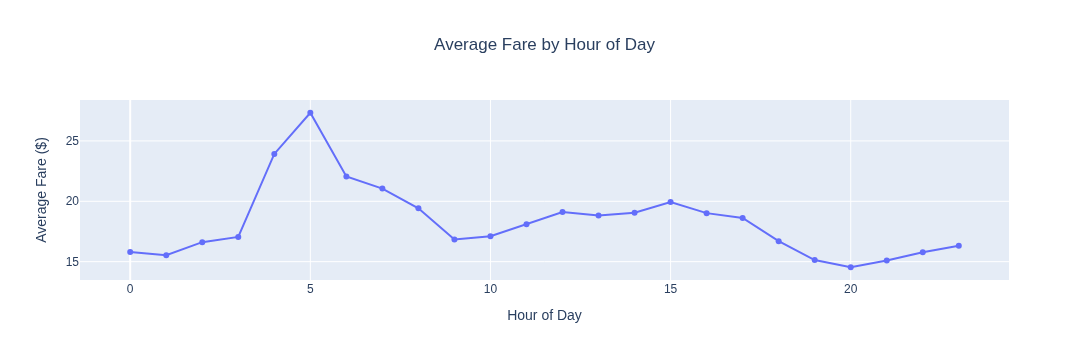

In [19]:
hourly_profile = (
    train_df
    .groupby('hour')
    .agg(
        average_fare=('fare', 'mean'),
        average_miles=('trip_miles', 'mean'),
        average_minutes=('trip_minutes', 'mean'),
        trips=('fare', 'size')
    )
    .reset_index()
)

display(hourly_profile.round(2))

fig = px.line(
    hourly_profile,
    x='hour',
    y='average_fare',
    markers=True,
    title='Average Fare by Hour of Day',
    labels={'hour': 'Hour of Day', 'average_fare': 'Average Fare ($)'}
)

fig.update_layout(title=dict(x=0.5, xanchor='center'))
fig.show()


### Why Try Polynomial Regression?

The hourly pattern is not a simple straight line. Distance, duration, speed, and relative demand may also have nonlinear relationships with fare.

So I keep the regression approach, but make it more flexible by adding polynomial terms.

For the Polynomial Ridge model, **hour is treated as a numeric variable and included in the polynomial expansion** together with distance, duration, relative demand, and average speed.

Because polynomial features create many correlated terms, I use **Ridge Regression** rather than ordinary least squares.

I do not manually choose the polynomial degree. Instead, I use **GridSearchCV** to determine which degree and Ridge regularization strength perform best.


# Part VI — Polynomial Ridge Regression

## 17. Define the Polynomial Ridge Features

### Numeric variables expanded polynomially
- trip distance
- trip duration
- hour
- relative demand
- average speed

### Categorical variables
- weekday
- month
- pickup area
- drop-off area
- route
- hour × weekday
- pickup area × hour
- drop-off area × hour
- holiday

The categorical interaction variables allow different locations to have different hourly patterns, while the polynomial terms capture global nonlinear relationships.


In [20]:
ridge_numeric = [
    'trip_miles', 'trip_minutes', 'hour',
    'demand_ratio', 'avg_speed_mph'
]

ridge_categorical = [
    'day_of_week', 'month',
    'pickup_community_area', 'dropoff_community_area',
    'route', 'hour_day', 'pickup_hour', 'dropoff_hour',
    'is_holiday'
]

ridge_features = ridge_numeric + ridge_categorical


##  Build the Polynomial Ridge Pipeline

`PolynomialFeatures` generates the nonlinear terms. `StandardScaler` places the numeric terms on comparable scales, and Ridge regularization controls the size of the coefficients.


In [21]:
numeric_pipeline = Pipeline([
    ('poly', PolynomialFeatures(include_bias=False)),
    ('scale', StandardScaler())
])

ridge_preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, ridge_numeric),
    (
        'categorical',
        OneHotEncoder(handle_unknown='ignore', min_frequency=25),
        ridge_categorical
    )
], sparse_threshold=0.3)

polynomial_ridge = Pipeline([
    ('preprocessor', ridge_preprocessor),
    ('ridge', Ridge(solver='lsqr'))
])


## Use a Training Subset for GridSearchCV

GridSearchCV fits many candidate models. Running every candidate on the full training set would be unnecessarily expensive.

I therefore use 100,000 rows from the **training set only** to select hyperparameters. The test set remains untouched.


In [22]:
tune_size = min(TUNE_SIZE, len(train_df))
tune_df = train_df.sample(n=tune_size, random_state=RANDOM_STATE)

X_tune = tune_df[ridge_features]
y_tune = tune_df['fare'].astype(float)

print(f'GridSearch tuning rows: {len(tune_df):,}')


GridSearch tuning rows: 100,000


## Grid Search for Polynomial Degree and Ridge Alpha

I test:

- polynomial degree 1, 2, and 3
- Ridge alpha from 0.1 to 1000

The best model is selected using cross-validated R².


In [23]:
param_grid = {
    'preprocessor__numeric__poly__degree': [1, 2, 3],
    'ridge__alpha': [0.1, 1, 10, 100, 1000]
}

scoring = {
    'R2': 'r2',
    'MAE': 'neg_mean_absolute_error',
    'RMSE': 'neg_root_mean_squared_error'
}

grid_search = GridSearchCV(
    polynomial_ridge,
    param_grid=param_grid,
    scoring=scoring,
    refit='R2',
    cv=3,
    n_jobs=-1,
    verbose=2
)

grid_search.fit(X_tune, y_tune)


Fitting 3 folds for each of 15 candidates, totalling 45 fits


,estimator,Pipeline(step...ver='lsqr'))])
,param_grid,"{'preprocessor__numeric__poly__degree': [1, 2, ...], 'ridge__alpha': [0.1, 1, ...]}"
,scoring,"{'MAE': 'neg_mean_absolute_error', 'R2': 'r2', 'RMSE': 'neg_root_mean_squared_error'}"
,n_jobs,-1
,refit,'R2'
,cv,3
,verbose,2
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('numeric', ...), ('categorical', ...)]"


## Inspect the GridSearch Results

In [24]:
print('Best parameters:', grid_search.best_params_)
print(f'Best cross-validation R²: {grid_search.best_score_:.4f}')

cv = pd.DataFrame(grid_search.cv_results_)

grid_results = pd.DataFrame({
    'degree': cv['param_preprocessor__numeric__poly__degree'].astype(int),
    'alpha': cv['param_ridge__alpha'].astype(float),
    'CV_R2': cv['mean_test_R2'],
    'CV_MAE': -cv['mean_test_MAE'],
    'CV_RMSE': -cv['mean_test_RMSE']
}).sort_values('CV_R2', ascending=False).reset_index(drop=True)

display(grid_results.round(4))


Best parameters: {'preprocessor__numeric__poly__degree': 1, 'ridge__alpha': 10}
Best cross-validation R²: 0.7648


,degree,alpha,CV_R2,CV_MAE,CV_RMSE
0,1,10.0,0.7648,4.4834,7.0945
1,1,100.0,0.7647,4.4635,7.0963
2,2,100.0,0.7647,4.4598,7.0980
3,2,10.0,0.7646,4.4821,7.0997
4,1,1.0,0.7640,4.5010,7.1066
5,1,0.1,0.7639,4.5046,7.1094
6,2,1.0,0.7634,4.4994,7.1177
7,2,0.1,0.7632,4.5030,7.1204
8,3,100.0,0.7608,4.4599,7.1578
9,1,1000.0,0.7571,4.5307,7.2100


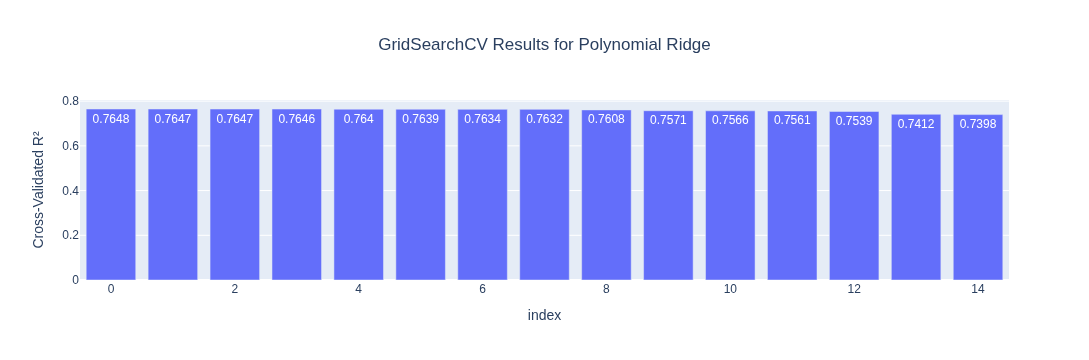

In [25]:
fig = px.bar(
    grid_results,
    x=grid_results.index,
    y='CV_R2',
    text=grid_results['CV_R2'].round(4),
    hover_data=['degree', 'alpha'],
    title='GridSearchCV Results for Polynomial Ridge',
    labels={'x': 'Candidate Rank', 'CV_R2': 'Cross-Validated R²'}
)

fig.update_layout(title=dict(x=0.5, xanchor='center'))
fig.show()


## Refit the Best Polynomial Ridge Model

GridSearchCV only selects the hyperparameters. I now refit the winning configuration using the **entire training set** and evaluate it once on the untouched test set.


In [26]:
ridge_model = grid_search.best_estimator_
ridge_model.fit(train_df[ridge_features], y_train)

ridge_pred = ridge_model.predict(test_df[ridge_features])
record_result('3. Polynomial Ridge', ridge_pred)


3. Polynomial Ridge                 R²=0.7724  MAE=$4.42  RMSE=$7.01


In [27]:
print(f'R² gain over Full Linear: {results[2]["R2"] - results[1]["R2"]:.4f}')
print(f'MAE improvement over Full Linear: ${results[1]["MAE"] - results[2]["MAE"]:.2f}')


R² gain over Full Linear: 0.0138
MAE improvement over Full Linear: $0.16


### What I Learn from Polynomial Ridge

Previous experiments showed Polynomial Ridge reaching approximately **R² = 0.77**.

This is better than the Full Linear Regression, but the improvement is smaller than the jump from the baseline to the Full Linear model.

At this point, the model already contains:

- nonlinear numeric terms
- many one-hot encoded location categories
- route categories
- time-location interaction categories

That makes me wonder whether a tree-based model can capture these relationships more naturally.

Instead of manually creating every interaction, I next try **Gradient Boosting**, which can discover nonlinear splits and interactions automatically.


# Part VII — Gradient Boosting

## Why Try Gradient Boosting?

The dataset now contains many categorical and interacting features. A linear model can represent them, but it requires many encoded columns and manually specified transformations.

Gradient Boosting builds a sequence of decision trees. Each new tree attempts to correct errors from the previous trees.

This allows the model to learn patterns such as:

- distance × duration
- hour × pickup area
- demand × location
- airport-related pricing

without explicitly writing every interaction formula.

The purpose is to test whether a much more flexible nonlinear model provides a **large** improvement over Ridge or only a modest one.


## Define Gradient Boosting Features

The tree model uses the same core trip, time, location, and demand information, plus the raw coordinates and straight-line-distance features that trees can use naturally.


In [29]:
gb_features = [
    'trip_miles', 'trip_minutes',
    'local_demand', 'typical_demand', 'demand_ratio',
    'avg_speed_mph',
    'hour', 'day_of_week', 'month',
    'pickup_area_cat', 'dropoff_area_cat',
    'is_holiday', 'is_weekend', 'outside_chicago', 'airport_trip',
    'pickup_lat', 'pickup_lon', 'dropoff_lat', 'dropoff_lon',
    'crow_fly_miles', 'detour_ratio'
]

gb_categorical = [
    'hour', 'day_of_week', 'month',
    'pickup_area_cat', 'dropoff_area_cat',
    'is_holiday', 'is_weekend', 'outside_chicago', 'airport_trip'
]


## Fit Gradient Boosting

In [30]:
gradient_boosting_model = HistGradientBoostingRegressor(
    loss='squared_error',
    learning_rate=0.1,
    max_iter=400,
    max_leaf_nodes=63,
    min_samples_leaf=50,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=20,
    categorical_features=gb_categorical,
    random_state=RANDOM_STATE
)

gradient_boosting_model.fit(train_df[gb_features], y_train)
gb_pred = gradient_boosting_model.predict(test_df[gb_features])

print('Boosting iterations used:', gradient_boosting_model.n_iter_)
record_result('4. Gradient Boosting', gb_pred)


Boosting iterations used: 279
4. Gradient Boosting                R²=0.7768  MAE=$4.25  RMSE=$6.94


# Part VIII — Compare the Four Models

Now that every model has been tested on the same observations, I can compare the gain from each increase in complexity.

The important question is not only **which model has the highest R²**, but also whether the improvement is large enough to justify the added complexity.


## Model Comparison Table

In [31]:
comparison = pd.DataFrame(results)

comparison['R2_Gain_vs_Baseline'] = comparison['R2'] - comparison.loc[0, 'R2']
comparison['MAE_Saved_vs_Baseline'] = comparison.loc[0, 'MAE'] - comparison['MAE']

comparison['R2_Gain_vs_Previous'] = comparison['R2'].diff()
comparison['MAE_Saved_vs_Previous'] = -comparison['MAE'].diff()

display(comparison.round(4))


,Model,R2,MAE,RMSE,R2_Gain_vs_Baseline,MAE_Saved_vs_Baseline,R2_Gain_vs_Previous,MAE_Saved_vs_Previous
0,1. Baseline Linear Regression,0.7273,4.8421,7.6672,0.0000,0.0000,NaN,NaN
1,2. Full Linear Regression,0.7586,4.5777,7.2140,0.0313,0.2644,0.0313,0.2644
2,3. Polynomial Ridge,0.7724,4.4216,7.0054,0.0450,0.4206,0.0138,0.1561
3,4. Gradient Boosting,0.7768,4.2463,6.9367,0.0495,0.5958,0.0044,0.1752


## Compare R²

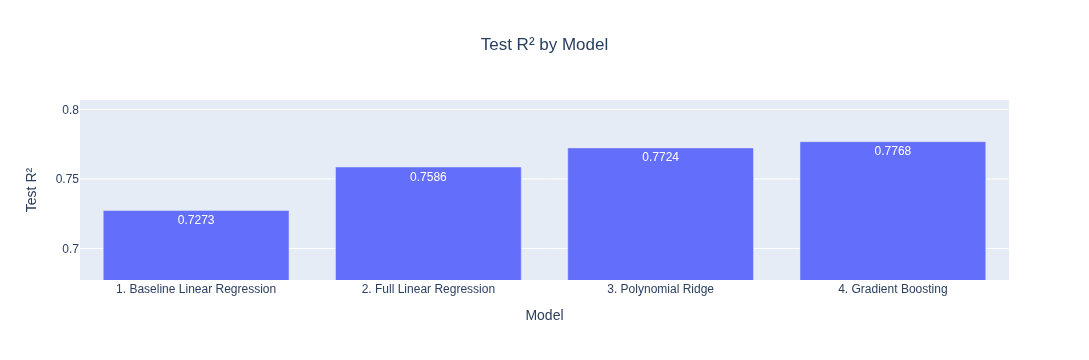

In [32]:
fig = px.bar(
    comparison,
    x='Model',
    y='R2',
    text=comparison['R2'].round(4),
    title='Test R² by Model',
    labels={'R2': 'Test R²'}
)

fig.update_yaxes(
    range=[max(0, comparison['R2'].min() - 0.05), min(1, comparison['R2'].max() + 0.03)]
)
fig.update_layout(title=dict(x=0.5, xanchor='center'))
fig.show()


## Compare MAE

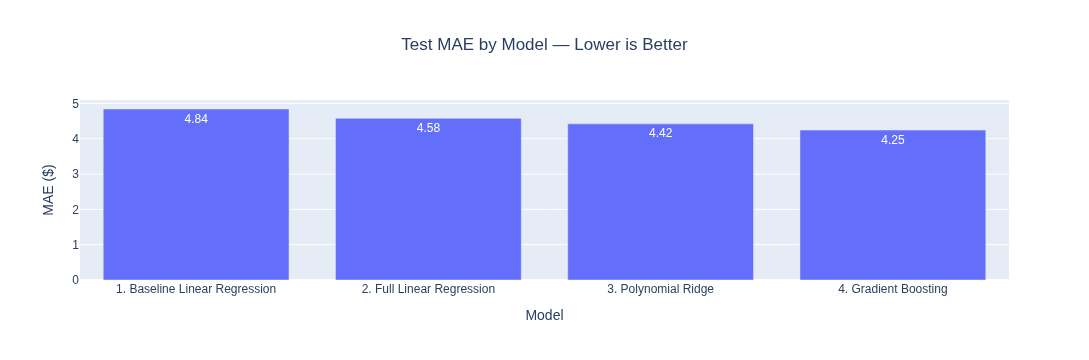

In [33]:
fig = px.bar(
    comparison,
    x='Model',
    y='MAE',
    text=comparison['MAE'].round(2),
    title='Test MAE by Model — Lower is Better',
    labels={'MAE': 'MAE ($)'}
)

fig.update_layout(title=dict(x=0.5, xanchor='center'))
fig.show()


## What Does the Model Progression Tell Me?

The expected pattern from earlier experiments is approximately:

**Baseline (0.73) -> Full Linear (0.76) -> Polynomial Ridge (0.77) -> Gradient Boosting (0.78)**

The largest improvement occurs when moving from the simple baseline to the richer linear model.

After that, increasingly complex models still improve prediction, but the gains become smaller.

That suggests:

- distance and duration explain most of the predictable fare variation
- time, location, and demand add important information
- nonlinear terms and interactions provide additional improvement
- a very flexible tree model may only improve performance modestly beyond Ridge

Because Ridge remains close to the strongest predictive model while being easier to interpret, I use it for the final hour-and-demand analysis.


# Part IX — Use Polynomial Ridge to Study Hour and Demand

Instead of interpreting hundreds of individual Ridge coefficients, I use **controlled prediction scenarios**.

I create a typical trip, hold its characteristics constant, and change only the variable I want to study.


## Construct a Typical Trip

In [34]:
typical_miles = train_df['trip_miles'].median()
typical_minutes = train_df['trip_minutes'].median()
typical_speed = train_df['avg_speed_mph'].median()

typical_pickup = int(train_df['pickup_community_area'].mode()[0])
typical_dropoff = int(train_df['dropoff_community_area'].mode()[0])
typical_day = int(train_df['day_of_week'].mode()[0])
typical_month = int(train_df['month'].mode()[0])

typical_route = f'{typical_pickup}_{typical_dropoff}'

print(f'Distance: {typical_miles:.2f} miles')
print(f'Duration: {typical_minutes:.2f} minutes')
print(f'Pickup area: {typical_pickup}')
print(f'Drop-off area: {typical_dropoff}')


Distance: 3.30 miles
Duration: 14.15 minutes
Pickup area: 8
Drop-off area: 8


## Predicted Fare by Hour

I create 24 copies of the same typical trip.

Everything stays constant except `hour`. Demand ratio is fixed at `1.0`, meaning normal demand.

This isolates the model's estimated hourly pricing pattern after controlling for the trip itself.


In [35]:
hour_rows = []

for hour in range(24):
    hour_rows.append({
        'trip_miles': typical_miles,
        'trip_minutes': typical_minutes,
        'hour': hour,
        'demand_ratio': 1.0,
        'avg_speed_mph': typical_speed,
        'day_of_week': typical_day,
        'month': typical_month,
        'pickup_community_area': typical_pickup,
        'dropoff_community_area': typical_dropoff,
        'route': typical_route,
        'hour_day': f'{hour}_{typical_day}',
        'pickup_hour': f'{typical_pickup}_{hour}',
        'dropoff_hour': f'{typical_dropoff}_{hour}',
        'is_holiday': 0
    })

hour_scenario = pd.DataFrame(hour_rows)
hour_scenario['predicted_fare'] = ridge_model.predict(hour_scenario[ridge_features])

hour_scenario['hour_label'] = hour_scenario['hour'].apply(
    lambda h: '12 AM' if h == 0 else '12 PM' if h == 12 else f'{h} AM' if h < 12 else f'{h - 12} PM'
)

display(hour_scenario[['hour_label', 'predicted_fare']])


,hour_label,predicted_fare
0,12 AM,13.939571
1,1 AM,14.106021
2,2 AM,15.417236
3,3 AM,13.662087
4,4 AM,13.859691
5,5 AM,12.008292
6,6 AM,9.976936
7,7 AM,10.885014
8,8 AM,12.221732
9,9 AM,11.626452


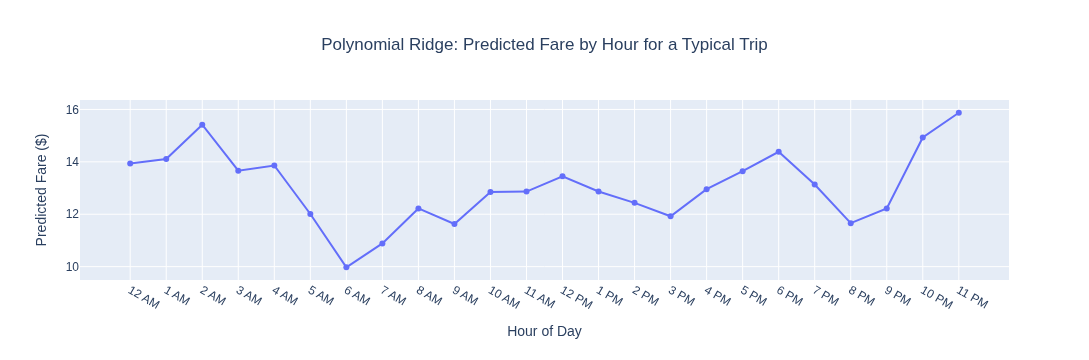

In [36]:
fig = px.line(
    hour_scenario,
    x='hour_label',
    y='predicted_fare',
    markers=True,
    title='Polynomial Ridge: Predicted Fare by Hour for a Typical Trip',
    labels={'hour_label': 'Hour of Day', 'predicted_fare': 'Predicted Fare ($)'},
    category_orders={'hour_label': hour_scenario['hour_label'].tolist()}
)

fig.update_layout(title=dict(x=0.5, xanchor='center'))
fig.show()


### Interpretation

The raw EDA showed average fare by hour, but raw hourly fare can be affected by differences in trip distance and duration.

This scenario holds distance, duration, route, weekday, month, and demand constant. The remaining pattern therefore gives a cleaner view of the **association between hour and predicted fare**.


## Predicted Fare by Relative Demand

Next, I hold the typical trip constant and vary relative local demand.

I compare:

- 50% of typical demand
- typical demand
- 150% of typical demand
- 200% of typical demand

This gives a surge-like interpretation without claiming that the public dataset contains the company's actual surge multiplier.


In [37]:
demand_rows = []

for hour in range(24):
    for demand_ratio in [0.5, 1.0, 1.5, 2.0]:
        demand_rows.append({
            'trip_miles': typical_miles,
            'trip_minutes': typical_minutes,
            'hour': hour,
            'demand_ratio': demand_ratio,
            'avg_speed_mph': typical_speed,
            'day_of_week': typical_day,
            'month': typical_month,
            'pickup_community_area': typical_pickup,
            'dropoff_community_area': typical_dropoff,
            'route': typical_route,
            'hour_day': f'{hour}_{typical_day}',
            'pickup_hour': f'{typical_pickup}_{hour}',
            'dropoff_hour': f'{typical_dropoff}_{hour}',
            'is_holiday': 0
        })

demand_scenario = pd.DataFrame(demand_rows)
demand_scenario['predicted_fare'] = ridge_model.predict(demand_scenario[ridge_features])

demand_scenario['hour_label'] = demand_scenario['hour'].apply(
    lambda h: '12 AM' if h == 0 else '12 PM' if h == 12 else f'{h} AM' if h < 12 else f'{h - 12} PM'
)

demand_scenario['demand_level'] = demand_scenario['demand_ratio'].map({
    0.5: '50% of Typical Demand',
    1.0: 'Typical Demand',
    1.5: '150% of Typical Demand',
    2.0: '200% of Typical Demand'
})


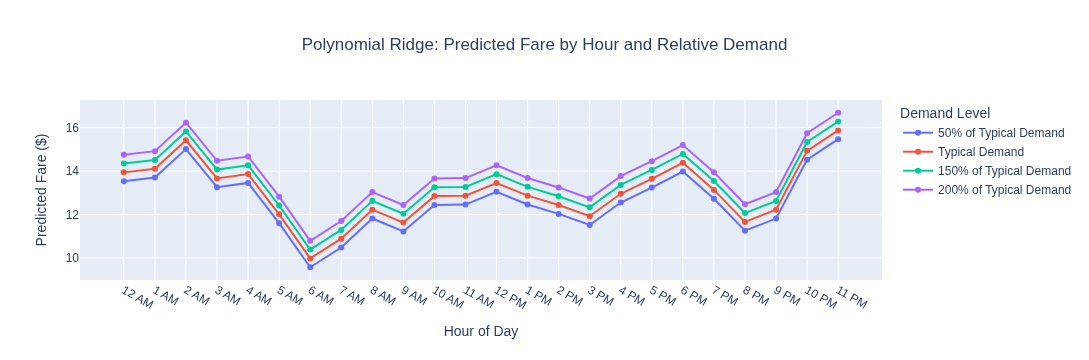

In [38]:
fig = px.line(
    demand_scenario,
    x='hour_label',
    y='predicted_fare',
    color='demand_level',
    markers=True,
    title='Polynomial Ridge: Predicted Fare by Hour and Relative Demand',
    labels={
        'hour_label': 'Hour of Day',
        'predicted_fare': 'Predicted Fare ($)',
        'demand_level': 'Demand Level'
    },
    category_orders={'hour_label': hour_scenario['hour_label'].tolist()}
)

fig.update_layout(title=dict(x=0.5, xanchor='center'))
fig.show()


## Quantify the Demand Association

In [39]:
low = demand_scenario[demand_scenario['demand_ratio'] == 0.5].sort_values('hour')['predicted_fare'].to_numpy()
normal = demand_scenario[demand_scenario['demand_ratio'] == 1.0].sort_values('hour')['predicted_fare'].to_numpy()
high = demand_scenario[demand_scenario['demand_ratio'] == 2.0].sort_values('hour')['predicted_fare'].to_numpy()

print(f'Average predicted change from 50% → 100% demand: ${np.mean(normal - low):.2f}')
print(f'Average predicted change from 100% → 200% demand: ${np.mean(high - normal):.2f}')
print(f'Average predicted change from 50% → 200% demand: ${np.mean(high - low):.2f}')


Average predicted change from 50% → 100% demand: $0.41
Average predicted change from 100% → 200% demand: $0.81
Average predicted change from 50% → 200% demand: $1.22


### Important Limitation

`local_demand` is based on completed rides. It does not contain:

- total ride requests
- available drivers
- actual supply-demand imbalance
- proprietary surge multipliers

Therefore, the demand result should be described as an **association**, not a causal estimate of the company's surge-pricing rule.


# Part X — Save Results

## Save Tables for the Report

In [40]:
comparison.to_csv(REPORTS_DIR / '04_model_comparison.csv', index=False)
grid_results.to_csv(REPORTS_DIR / '04_polynomial_ridge_gridsearch.csv', index=False)
hour_scenario.to_csv(REPORTS_DIR / '04_ridge_hour_scenario.csv', index=False)
demand_scenario.to_csv(REPORTS_DIR / '04_ridge_demand_scenario.csv', index=False)

print('Results saved to ../reports/')


Results saved to ../reports/
